In [7]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt

from src.preprocess import get_train_test_split, clean_and_engineer, NUMERIC_FEATURES
from src.explain import get_parts, make_explainer, shap_matrix, group_shap, explain_customer
from src.risk import load_config, risk_tier, predict_label, suggest_action

X_train, X_test, y_train, y_test = get_train_test_split("../data/telco_churn.csv")
pipe = joblib.load("../models/churn_model.joblib")
cfg = load_config("../models/model_config.json")

prep, model, names = get_parts(pipe)
explainer = make_explainer(model, prep.transform(X_train))

X_explain = X_test.sample(n=min(1000, len(X_test)), random_state=42)
Xt = prep.transform(X_explain)
sv, base = shap_matrix(explainer, Xt)

print(cfg["model_name"], "| SHAP matrix:", sv.shape, "| features:", len(names))

gradient_boosting | SHAP matrix: (1000, 26) | features: 26


In [8]:
def raw_output(model, X):
    if hasattr(model, "decision_function"):            # Logistic Regression, Gradient Boosting
        return model.decision_function(X)
    if model.__class__.__name__ == "XGBClassifier":
        return model.predict(X, output_margin=True)
    return model.predict_proba(X)[:, 1]                # Random Forest, Decision Tree

reconstructed = base + sv.sum(axis=1)
print("Max difference:", np.abs(reconstructed - raw_output(model, Xt)).max().round(5))

Max difference: 0.0


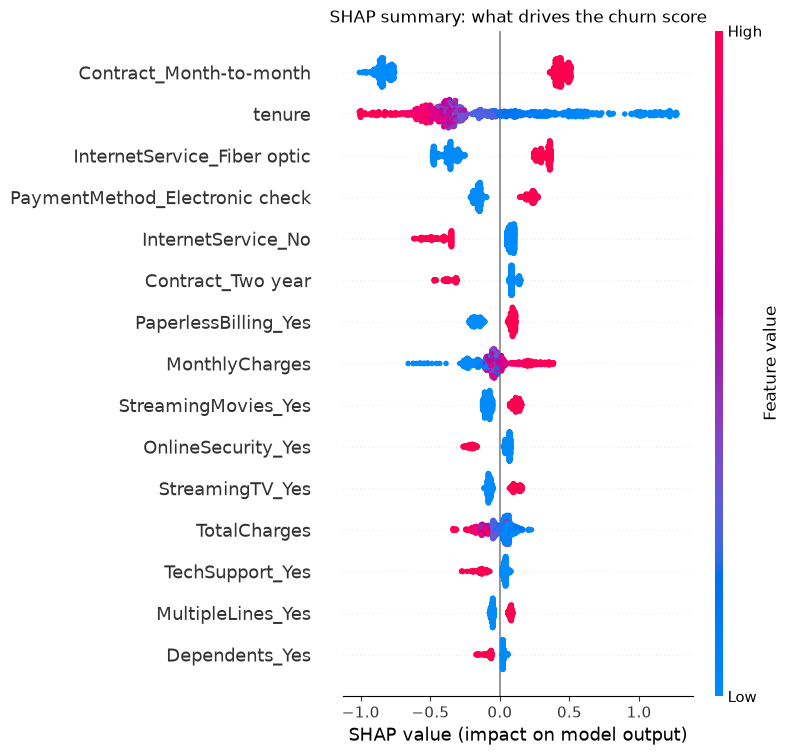

In [9]:
shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
plt.title("SHAP summary: what drives the churn score")
plt.savefig("../reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

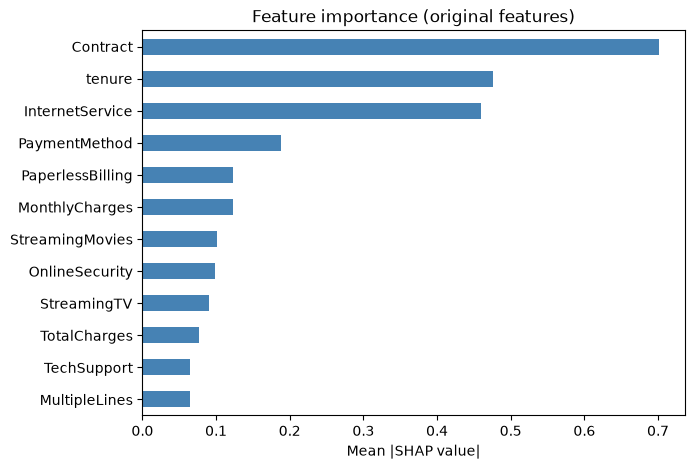

Contract            0.701
tenure              0.477
InternetService     0.459
PaymentMethod       0.188
PaperlessBilling    0.123
MonthlyCharges      0.123
StreamingMovies     0.101
OnlineSecurity      0.098
StreamingTV         0.091
TotalCharges        0.077
TechSupport         0.065
MultipleLines       0.064
dtype: float64

In [10]:
g = group_shap(sv, names)
importance = g.abs().mean().sort_values(ascending=False)

importance.head(12)[::-1].plot(kind="barh", figsize=(7, 5), color="steelblue")
plt.xlabel("Mean |SHAP value|")
plt.title("Feature importance (original features)")
plt.savefig("../reports/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance.head(12).round(3)

In [11]:
cleaned = clean_and_engineer(X_explain)

for feat in ["Contract", "InternetService", "TechSupport", "PaymentMethod"]:
    out = (pd.DataFrame({feat: cleaned[feat].values, "avg_SHAP": g[feat].values})
           .groupby(feat)["avg_SHAP"].agg(["mean", "count"]).round(3))
    print(out, "\n")

                 mean  count
Contract                    
Month-to-month  0.510    556
One year       -0.610    213
Two year       -1.248    231 

                  mean  count
InternetService              
DSL             -0.309    335
Fiber optic      0.399    439
No              -0.798    226 

              mean  count
TechSupport              
No           0.040    733
Yes         -0.132    267 

                            mean  count
PaymentMethod                          
Bank transfer (automatic) -0.164    201
Credit card (automatic)   -0.159    214
Electronic check           0.229    349
Mailed check              -0.173    236 



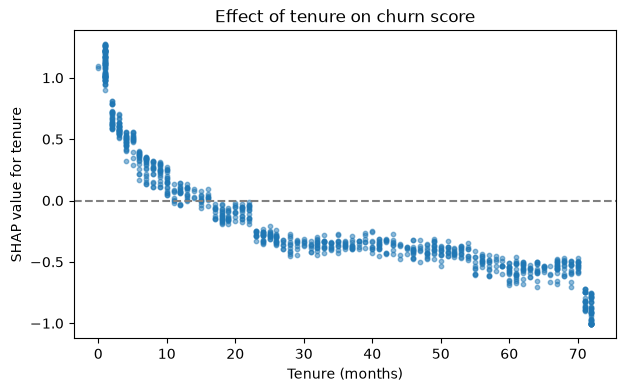

In [12]:
plt.figure(figsize=(7, 4))
plt.scatter(cleaned["tenure"], g["tenure"], s=10, alpha=0.5)
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("Tenure (months)"); plt.ylabel("SHAP value for tenure")
plt.title("Effect of tenure on churn score")
plt.savefig("../reports/shap_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

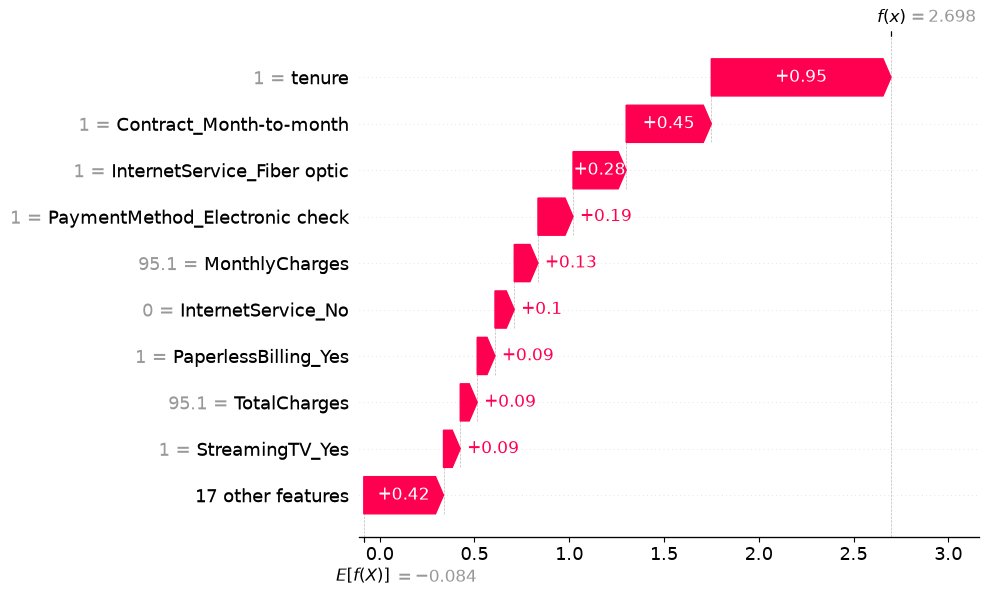

In [13]:
scores = pipe.predict_proba(X_explain)[:, 1]
i = int(np.argmax(scores))                # highest-scoring customer; try a low-risk one too

# Show real values (not standardized ones) on the plot
scaler = prep.named_steps["encode_scale"].named_transformers_["num"]
n_num = len(NUMERIC_FEATURES)             # numeric columns come first in the output
display = Xt.copy()
display[:, :n_num] = scaler.inverse_transform(Xt[:, :n_num])

exp = shap.Explanation(values=sv[i], base_values=base,
                       data=display[i], feature_names=names)
shap.plots.waterfall(exp, max_display=10, show=False)
plt.savefig("../reports/shap_waterfall_example.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
row = X_explain.iloc[[i]]
score = float(pipe.predict_proba(row)[0, 1])
drivers = explain_customer(pipe, explainer, row, top_n=3)
reasons, actions = suggest_action(drivers["increasing"])
r = clean_and_engineer(row).iloc[0]

label = "Risk score" if not cfg["score_is_calibrated"] else "Churn probability"
print(f"Customer ID: {r['customerID']}")
print(f"{risk_tier(score, cfg)} risk | {label}: {score:.0%}")
print(f"- Contract: {r['Contract']}")
print(f"- Tenure: {r['tenure']} months")
print(f"- Monthly charges: ${r['MonthlyCharges']:.2f}")
print(f"- Predicted churn: {predict_label(score, cfg)}")
print("- Top reasons:", "; ".join(reasons))
print("- Suggested action:", " | ".join(actions))

Customer ID: 5178-LMXOP
High risk | Risk score: 94%
- Contract: Month-to-month
- Tenure: 1 months
- Monthly charges: $95.10
- Predicted churn: Yes
- Top reasons: Short tenure (first year); Month-to-month contract; Fiber optic service
- Suggested action: Schedule an onboarding check-in call and welcome offer | Offer a discount to move to a 1- or 2-year contract | Review price and service quality; offer a plan check-up


In [15]:
from collections import Counter

high_idx = np.where(scores >= cfg["high_min"])[0][:200]
covered, counter = 0, Counter()

for j in high_idx:
    d = explain_customer(pipe, explainer, X_explain.iloc[[j]], top_n=3)
    _, acts = suggest_action(d["increasing"])
    if acts != ["Offer a suitable retention plan"]:
        covered += 1
    counter.update(acts)

print(f"High-risk customers checked: {len(high_idx)}")
print(f"Got at least one specific action: {covered / max(len(high_idx), 1):.0%}")
pd.Series(counter).sort_values(ascending=False).to_frame("times suggested")

High-risk customers checked: 105
Got at least one specific action: 100%


,times suggested
Offer a discount to move to a 1- or 2-year contract,105
Review price and service quality; offer a plan check-up,95
Schedule an onboarding check-in call and welcome offer,94
Offer a small incentive to switch to auto-pay,18
Review the plan; offer a bundle or loyalty discount,1
